In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("C:\\Users\\user\\Desktop\\Colab Notebooks\\homework4\\course_lead_scoring_2026.csv")


In [8]:
df.shape

(5000, 9)

In [9]:
df.info


<bound method DataFrame.info of          lead_source       industry employment_status       location  \
0     organic_search     technology          employed         europe   
1       social_media     technology          employed  south_america   
2           referral         retail          employed         europe   
3           paid_ads  manufacturing           student            NaN   
4           referral  manufacturing           student  north_america   
...              ...            ...               ...            ...   
4995  organic_search      education          employed           asia   
4996             NaN     technology          employed  north_america   
4997  organic_search        finance          employed           asia   
4998        referral     technology          employed         africa   
4999        referral     technology          employed         europe   

      annual_income  number_of_courses_viewed  interaction_count  lead_score  \
0           88160.0    

# Data Preparation

## making everything uniform

In [3]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

In [6]:
df.head(5)

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [7]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

## chaecking for missing values

In [10]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [11]:
categorical = list(
    df.select_dtypes(include=["object"]).columns
)

numerical = list(
    df.select_dtypes(
        include=["int64", "float64"]
    ).columns
)

for col in categorical:
    df[col] = df[col].fillna("NA")

for col in numerical:
    df[col] = df[col].fillna(0.0)

C:\Users\user\AppData\Local\Temp\ipykernel_6076\1714173311.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include=["object"]).columns


In [12]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

## Setting up the validation framework

In [115]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
len(df_train), len(df_val), len(df_test)


(3000, 1000, 1000)

In [116]:
print('converted' in df_train.columns)
print('converted' in df_val.columns)

True
True


In [118]:
from sklearn.metrics import roc_auc_score

numerical_features = [
    'lead_score',
    'number_of_courses_viewed',
    'interaction_count',
    'annual_income'
]

for feature in numerical_features:
    auc = roc_auc_score(
        df_train['converted'],
        df_train[feature]
    )

    if auc < 0.5:
        auc = roc_auc_score(
            df_train['converted'],
            -df_train[feature]
        )

    print(f'{feature}: {auc:.3f}')

lead_score: 0.788
number_of_courses_viewed: 0.723
interaction_count: 0.765
annual_income: 0.608


## resetting the index

In [14]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [117]:
print('converted' in df_train.columns)
print('converted' in df_val.columns)

True
True


## isolating the target

In [15]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [16]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

## EDA

In [17]:
df_full_train = df_full_train.reset_index(drop=True)

In [18]:
df_full_train.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

## Looking at the target: The converted

In [21]:
df_full_train["converted"].value_counts(normalize=True)

converted
1    0.57875
0    0.42125
Name: proportion, dtype: float64

In [22]:
df_full_train.converted.mean()

np.float64(0.57875)

In [23]:
df_full_train['converted'].value_counts()

converted
1    2315
0    1685
Name: count, dtype: int64

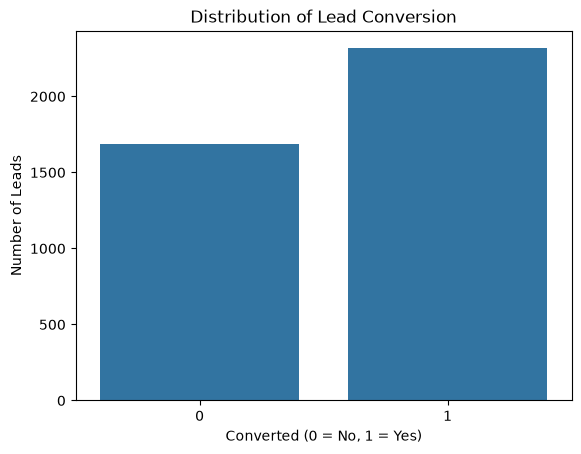

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df_full_train, x="converted")
plt.title("Distribution of Lead Conversion")
plt.xlabel("Converted (0 = No, 1 = Yes)")
plt.ylabel("Number of Leads")
plt.show()

## looking at the numerical features

In [26]:
numerical = df_full_train.select_dtypes(include="number").columns.tolist()
numerical.remove("converted")

print(numerical)

['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


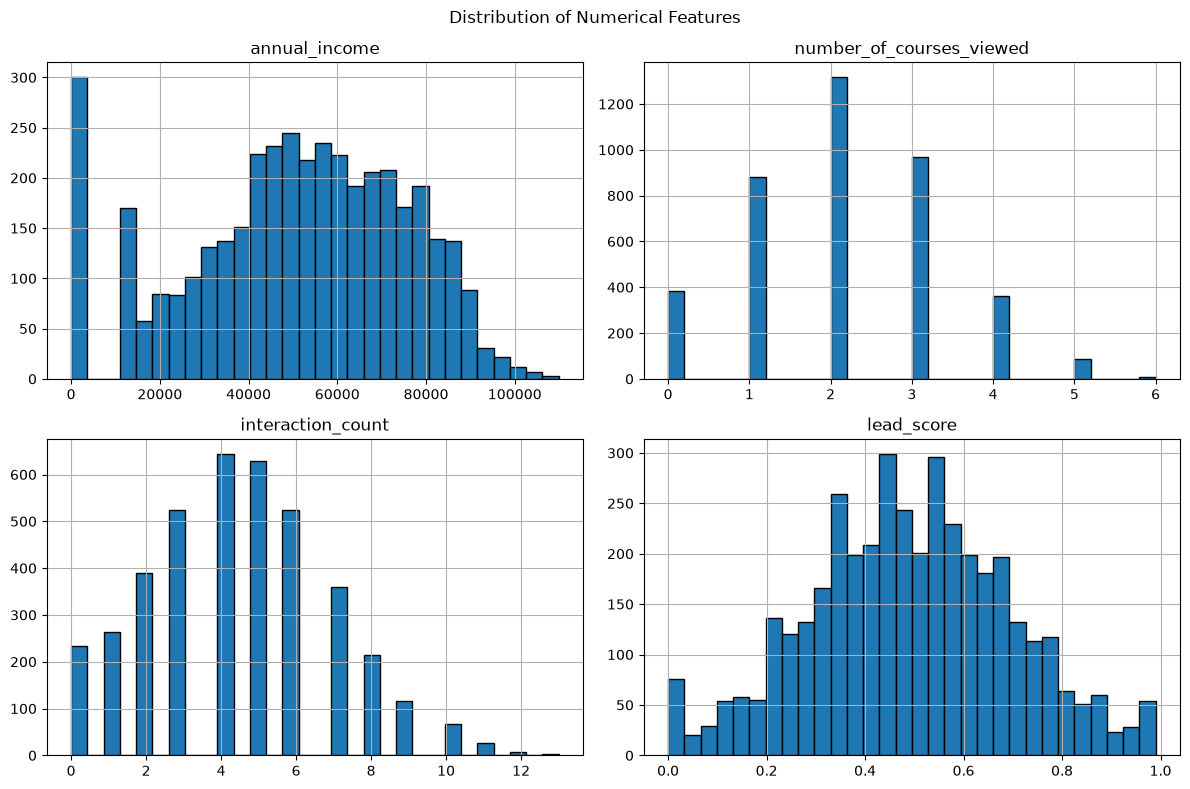

In [27]:
df_full_train[numerical].hist(
    figsize=(12, 8),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

## checking for outliers 

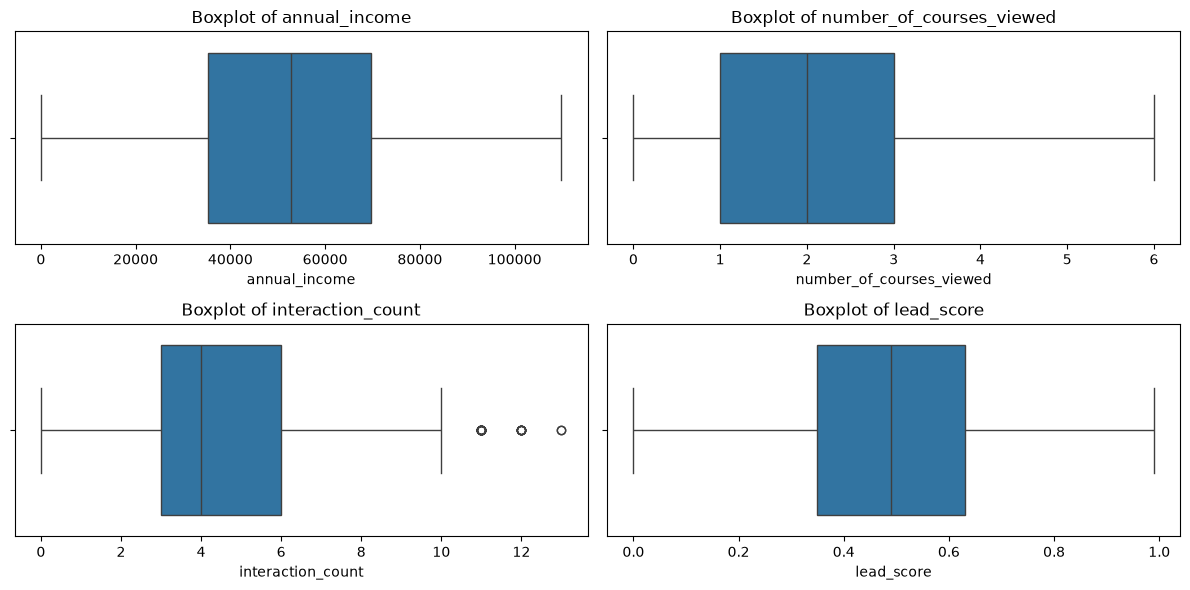

In [28]:
plt.figure(figsize=(12, 6))

for i, col in enumerate(numerical, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(data=df_full_train, x=col)
    plt.title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

## explore relationship with converted

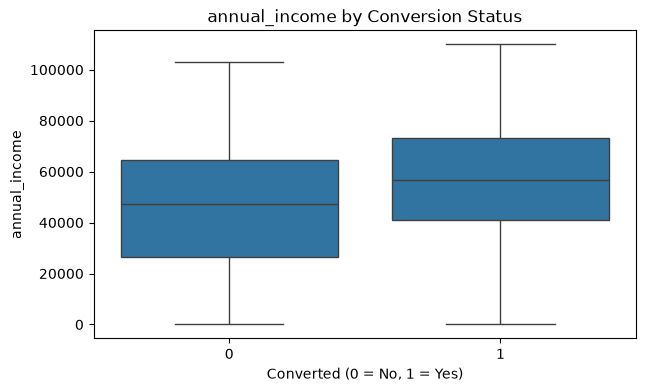

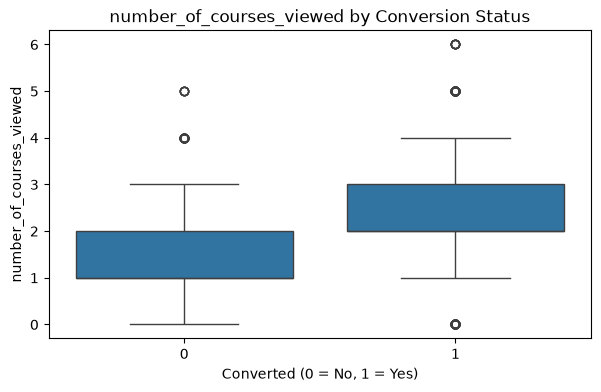

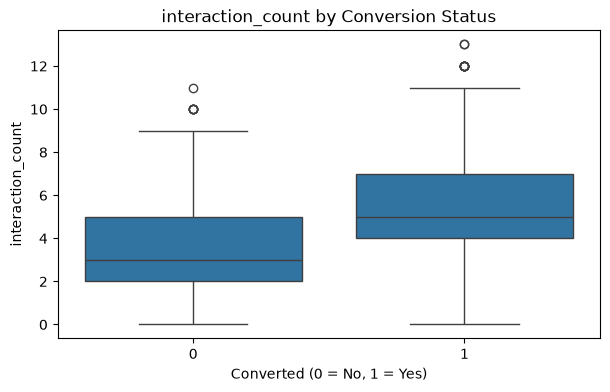

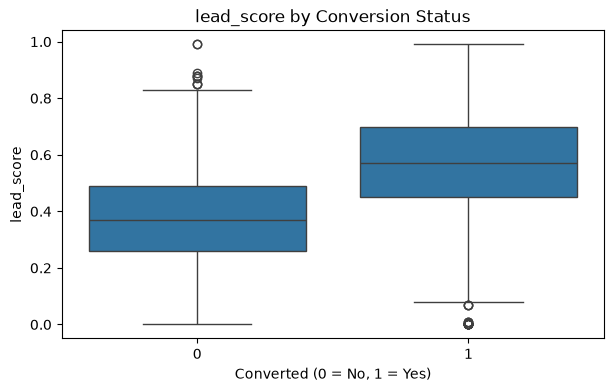

In [29]:
for col in numerical:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df_full_train,
        x="converted",
        y=col
    )

    plt.title(f"{col} by Conversion Status")
    plt.xlabel("Converted (0 = No, 1 = Yes)")
    plt.show()

## Global mean and median

In [31]:
df_full_train.groupby("converted")[numerical].mean().T

converted,0,1
annual_income,45019.411276,54599.685097
number_of_courses_viewed,1.535905,2.479482
interaction_count,3.163205,5.401296
lead_score,0.373917,0.574022


In [32]:
df_full_train.groupby("converted")[numerical].median().T

converted,0,1
annual_income,47301.00,56734.00
number_of_courses_viewed,1.00,2.00
interaction_count,3.00,5.00
lead_score,0.37,0.57


## explore the categorical features

In [33]:
categorical = df_full_train.select_dtypes(
    exclude="number"
).columns.tolist()

print(categorical)

['lead_source', 'industry', 'employment_status', 'location']


#### display most common values

In [37]:
for col in categorical:
    print(f"\n{col}")
    print(df_full_train[col].value_counts().head(10))


lead_source
lead_source
organic_search    994
paid_ads          906
social_media      849
referral          627
events            505
NA                119
Name: count, dtype: int64

industry
industry
technology       955
retail           742
healthcare       661
finance          569
education        496
manufacturing    377
NA               200
Name: count, dtype: int64

employment_status
employment_status
employed         2113
student           596
self_employed     569
unemployed        566
NA                156
Name: count, dtype: int64

location
location
north_america    1090
europe            903
asia              839
south_america     610
africa            391
NA                167
Name: count, dtype: int64


## compare cartegorical features with converted

In [38]:
for col in categorical:
    conversion_rate = (
        df_full_train.groupby(col, dropna=False)["converted"]
        .mean()
        .sort_values(ascending=False)
    )

    print(f"\nConversion rate by {col}:")
    print(conversion_rate)


Conversion rate by lead_source:
lead_source
referral          0.767145
organic_search    0.679074
NA                0.579832
social_media      0.568905
paid_ads          0.434879
events            0.421782
Name: converted, dtype: float64

Conversion rate by industry:
industry
technology       0.627225
NA               0.600000
finance          0.595782
manufacturing    0.567639
healthcare       0.562784
retail           0.556604
education        0.520161
Name: converted, dtype: float64

Conversion rate by employment_status:
employment_status
employed         0.666351
NA               0.602564
self_employed    0.553603
student          0.434564
unemployed       0.422261
Name: converted, dtype: float64

Conversion rate by location:
location
asia             0.601907
europe           0.600221
north_america    0.579817
NA               0.562874
south_america    0.545902
africa           0.534527
Name: converted, dtype: float64


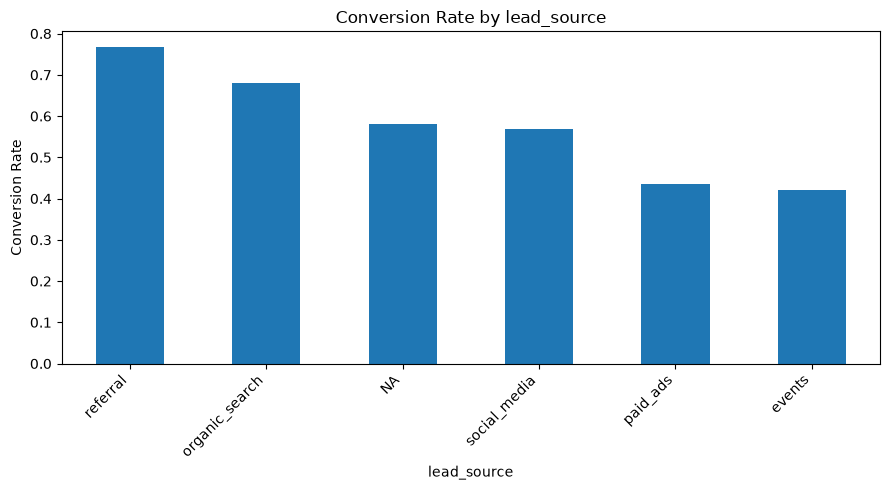

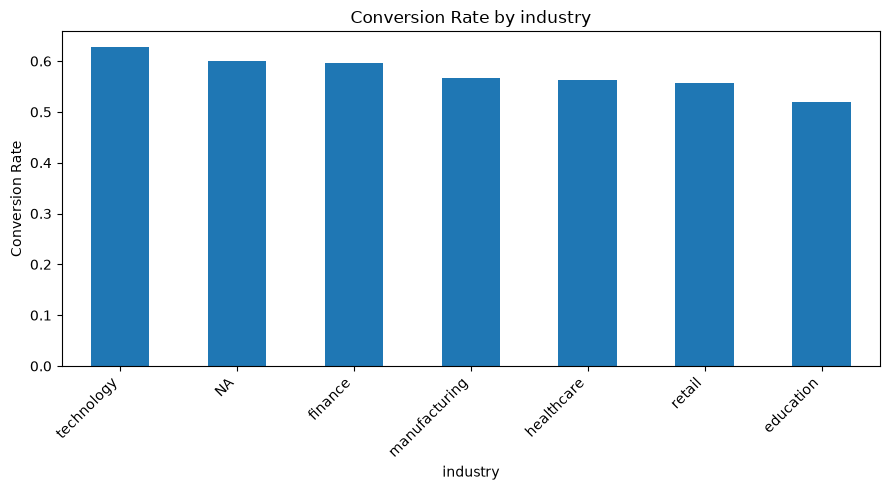

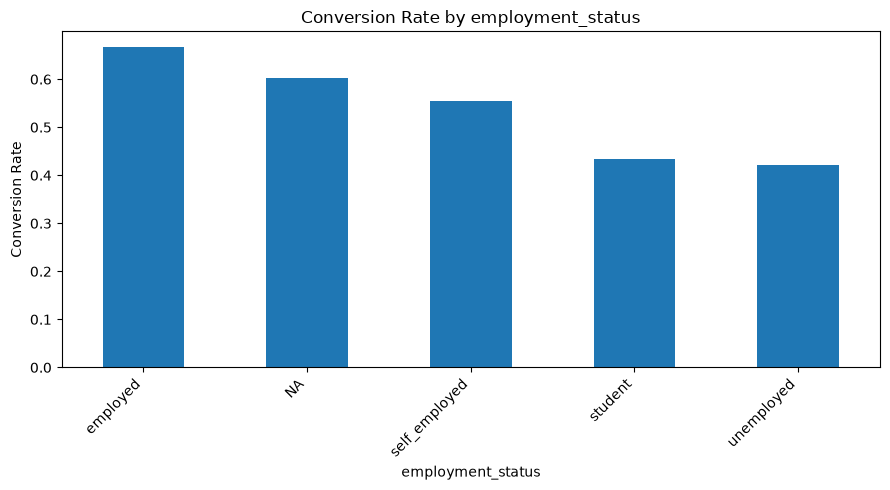

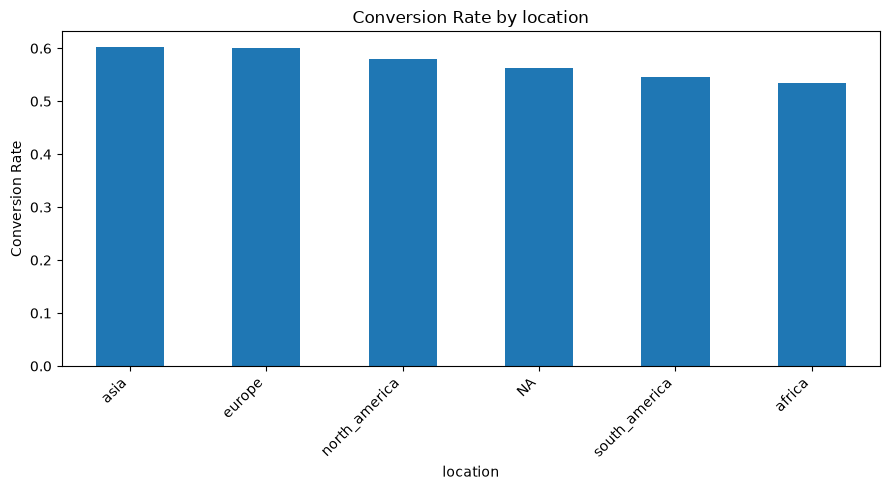

In [39]:
for col in categorical:
    rates = (
        df_full_train.groupby(col, dropna=False)["converted"]
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(9, 5))
    rates.plot(kind="bar")
    plt.title(f"Conversion Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Conversion Rate")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## feature importance: Mutual information

In [40]:
from sklearn.metrics import mutual_info_score
from sklearn.feature_selection import mutual_info_classif

In [41]:
categorical = df_full_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print(categorical)

['lead_source', 'industry', 'employment_status', 'location']


C:\Users\user\AppData\Local\Temp\ipykernel_6076\3402412662.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = df_full_train.select_dtypes(


In [42]:
mutual_info_score(df_full_train.converted, df_full_train.lead_source)

0.0333047794986628

In [43]:
def mutual_info_converted_score(series):
    return mutual_info_score(series, df_full_train.converted)

In [44]:
mi = df_full_train[categorical].apply(mutual_info_converted_score)
mi.sort_values(ascending=False)

lead_source          0.033305
employment_status    0.021988
industry             0.002456
location             0.001193
dtype: float64

## feature importance: Correlation

In [49]:
correlations = (
    df_full_train[numerical + ["converted"]]
    .corr()["converted"]
    .drop("converted")
    .sort_values(ascending=False)
)

print(correlations)

lead_score                  0.482188
interaction_count           0.451268
number_of_courses_viewed    0.391005
annual_income               0.189723
Name: converted, dtype: float64


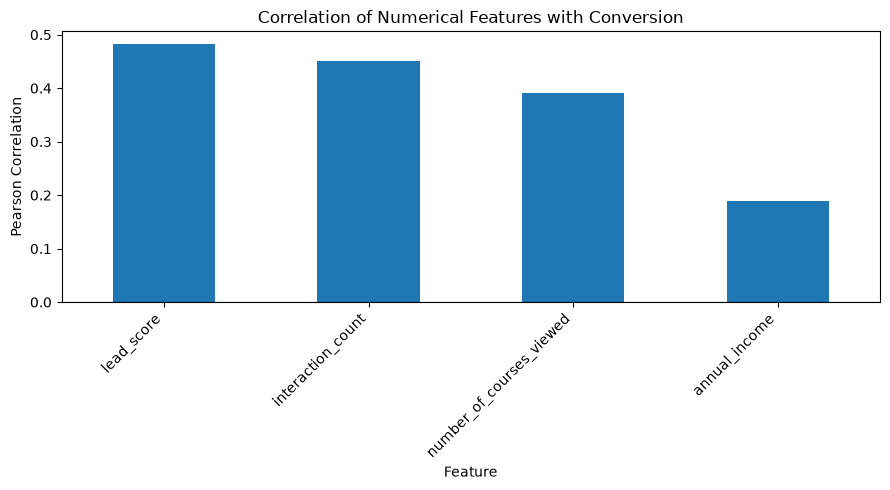

In [50]:
import matplotlib.pyplot as plt

correlations.plot(kind="bar", figsize=(9, 5))

plt.title("Correlation of Numerical Features with Conversion")
plt.xlabel("Feature")
plt.ylabel("Pearson Correlation")
plt.axhline(y=0, color="black", linewidth=0.8)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

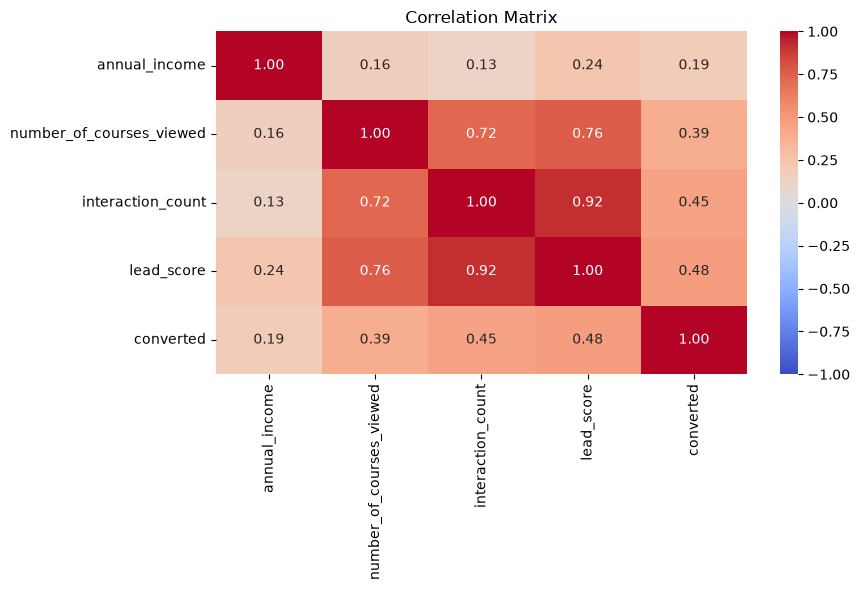

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = df_full_train[numerical + ["converted"]].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [120]:
# 1. Separate the target
y_train = df_train['converted'].values
y_val = df_val['converted'].values

# 2. Select features, excluding converted
train_dict = df_train[categorical + numerical].to_dict(
    orient='records'
)
val_dict = df_val[categorical + numerical].to_dict(
    orient='records'
)

Validation ROC AUC: 0.732


## one hot encodding

In [52]:
dicts = df[categorical + numerical].to_dict(orient='records')

In [53]:
from sklearn.feature_extraction import DictVectorizer

In [54]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

In [55]:
X_train.shape

(3000, 28)

## encodding the validation set

In [56]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

# Logistic Regression

In [57]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [58]:
sigmoid(10000)

np.float64(1.0)

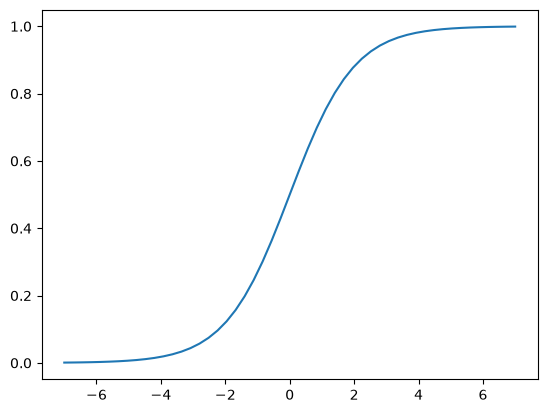

In [59]:
z = np.linspace(-7, 7, 51)
plt.plot(z, sigmoid(z))

## Implementing the Logistic Regression

In [61]:
def logistic_regression(xi):
    score = w0
    
    for j in range(len(w)):
        score = score + xi[j] * w[j]

        
    result = sigmoid(score)  
    return result

In [122]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)

model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)

print(f'Validation ROC AUC: {auc:.3f}')

Validation ROC AUC: 0.732


In [96]:
y_pred = model.predict_proba(X_val_scaled)[:, 1]
y_pred


array([0.15632053, 0.86157932, 0.47384676, 0.40166037, 0.87774352,
       0.69312304, 0.12773592, 0.30364737, 0.74902602, 0.43675825,
       0.97346239, 0.06253735, 0.25374889, 0.53601307, 0.43203615,
       0.12657828, 0.25548643, 0.82172165, 0.60685643, 0.43366912,
       0.31512378, 0.71632244, 0.65667433, 0.70848095, 0.69098108,
       0.25555885, 0.70427496, 0.25735043, 0.8700447 , 0.24471202,
       0.79833527, 0.72375886, 0.32774905, 0.86255647, 0.39712024,
       0.70998371, 0.66165734, 0.65848877, 0.59542592, 0.75465994,
       0.59580373, 0.79102353, 0.21865645, 0.59888618, 0.79187728,
       0.08522514, 0.79037791, 0.78671101, 0.44774649, 0.36404808,
       0.87702103, 0.73351383, 0.26225611, 0.19408473, 0.14658334,
       0.77971431, 0.86049621, 0.57578469, 0.45897104, 0.41517819,
       0.49565214, 0.51211339, 0.56950797, 0.67032554, 0.35537045,
       0.70605465, 0.97630294, 0.83175136, 0.76086158, 0.14846979,
       0.84317969, 0.64330584, 0.93561689, 0.90822378, 0.73429

In [97]:
converted_decision = (y_pred >= 0.5)
print("AFTER PREDICTION")
print("Correct:", (y_val == converted_decision).sum())
print("Accuracy:", (y_val == converted_decision).mean())


AFTER PREDICTION
Correct: 717
Accuracy: 0.717


In [87]:
dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3)))

{'annual_income': np.float64(0.149),
 'employment_status=NA': np.float64(0.058),
 'employment_status=employed': np.float64(0.106),
 'employment_status=self_employed': np.float64(-0.068),
 'employment_status=student': np.float64(-0.104),
 'employment_status=unemployed': np.float64(-0.009),
 'industry=NA': np.float64(0.029),
 'industry=education': np.float64(-0.048),
 'industry=finance': np.float64(-0.035),
 'industry=healthcare': np.float64(-0.038),
 'industry=manufacturing': np.float64(0.038),
 'industry=retail': np.float64(-0.014),
 'industry=technology': np.float64(0.071),
 'interaction_count': np.float64(0.43),
 'lead_score': np.float64(0.596),
 'lead_source=NA': np.float64(-0.016),
 'lead_source=events': np.float64(-0.06),
 'lead_source=organic_search': np.float64(0.082),
 'lead_source=paid_ads': np.float64(-0.098),
 'lead_source=referral': np.float64(0.113),
 'lead_source=social_media': np.float64(-0.03),
 'location=NA': np.float64(0.013),
 'location=africa': np.float64(-0.081),
 

## checking how many characters does the model predict correctly

In [101]:
(y_val == converted_decision).sum()

np.int64(553)

In [102]:
from sklearn.metrics import accuracy_score

accuracy_score(y_val, y_pred >= 0.5)

0.553

### Checking different thresholds

In [103]:
thresholds = np.linspace(0, 1, 21)

scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    print('%.2f %.3f' % (t, score))
    scores.append(score)

0.00 0.586
0.05 0.586
0.10 0.586
0.15 0.586
0.20 0.586
0.25 0.587
0.30 0.581
0.35 0.569
0.40 0.559
0.45 0.545
0.50 0.553
0.55 0.535
0.60 0.521
0.65 0.502
0.70 0.476
0.75 0.464
0.80 0.445
0.85 0.427
0.90 0.410
0.95 0.414
1.00 0.414


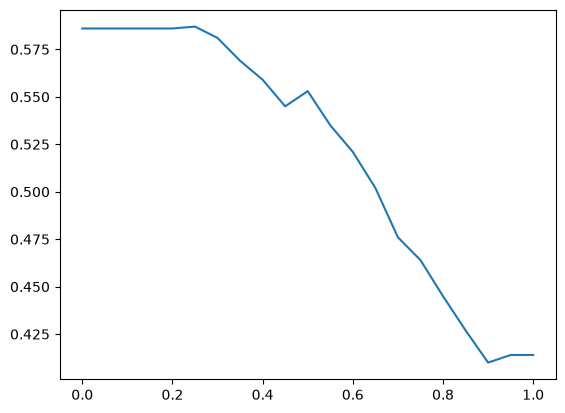

In [104]:
plt.plot(thresholds, scores)

## Dummy model

In [105]:
from collections import Counter
Counter(y_pred>=1.0)

Counter({np.False_: 1000})

In [106]:
1 - y_val.mean()

np.float64(0.41400000000000003)

In [111]:
print(df_full_train.columns.tolist())

['lead_source', 'industry', 'employment_status', 'location', 'annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score', 'converted']


# ROC AUC

In [123]:
from sklearn.metrics import roc_auc_score

y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)

print(f'Validation ROC AUC: {auc:.3f}')

Validation ROC AUC: 0.732


## calculating precision and recall


In [126]:

from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(0, 1.01, 0.01)

results = []

for t in thresholds:
    y_pred_binary = (y_pred >= t).astype(int)

    precision = precision_score(
        y_val, y_pred_binary, zero_division=0
    )
    recall = recall_score(
        y_val, y_pred_binary, zero_division=0
    )

    results.append({
        'threshold': t,
        'precision': precision,
        'recall': recall
    })

results_df = pd.DataFrame(results)
results_df.head()

,threshold,precision,recall
0,0.00,0.586,1.0
1,0.01,0.586,1.0
2,0.02,0.586,1.0
3,0.03,0.586,1.0
4,0.04,0.586,1.0


In [127]:
results_df['difference'] = abs(
    results_df['precision'] - results_df['recall']
)

valid_results = results_df[
    ~(
        (results_df['precision'] == 0) &
        (results_df['recall'] == 0)
    )
]

best_threshold = valid_results.loc[
    valid_results['difference'].idxmin()
]

print(best_threshold)

threshold     0.630000
precision     0.732759
recall        0.725256
difference    0.007503
Name: 63, dtype: float64


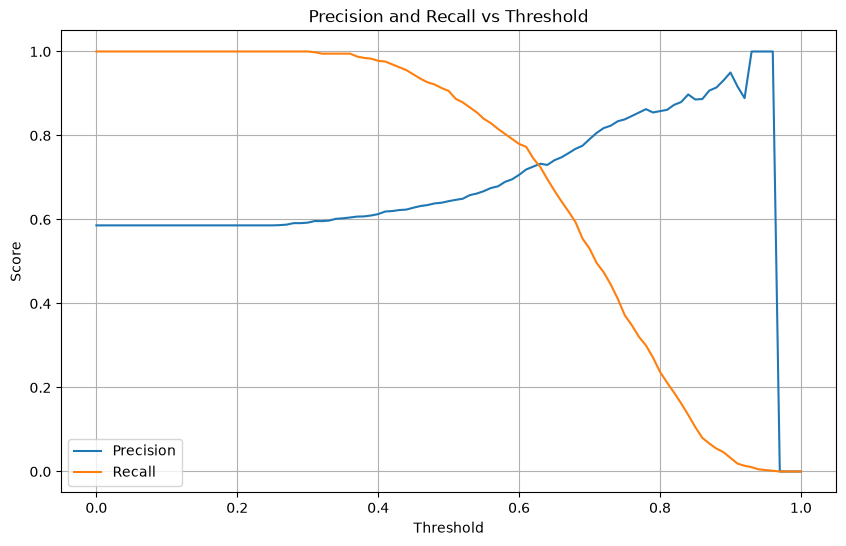

In [128]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    results_df['threshold'],
    results_df['precision'],
    label='Precision'
)
plt.plot(
    results_df['threshold'],
    results_df['recall'],
    label='Recall'
)

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(True)
plt.show()

## F1 score

In [130]:
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd

thresholds = np.arange(0, 1.01, 0.01)

f1_results = []

for t in thresholds:
    y_pred_binary = (y_pred >= t).astype(int)

    f1 = f1_score(
        y_val,
        y_pred_binary,
        zero_division=0
    )

    f1_results.append({
        'threshold': t,
        'f1': f1
    })

f1_df = pd.DataFrame(f1_results)

best_f1 = f1_df.loc[f1_df['f1'].idxmax()]

print(best_f1)

threshold    0.410000
f1           0.757616
Name: 41, dtype: float64


## 5-Fold CV

In [131]:
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import numpy as np

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_fold_train = df_full_train.iloc[train_idx]
    df_fold_val = df_full_train.iloc[val_idx]

    y_fold_train = df_fold_train['converted'].values
    y_fold_val = df_fold_val['converted'].values

    train_dicts = df_fold_train[categorical + numerical].to_dict(orient='records')
    val_dicts = df_fold_val[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_fold_train = dv.fit_transform(train_dicts)
    X_fold_val = dv.transform(val_dicts)

    model = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000
    )
    model.fit(X_fold_train, y_fold_train)

    y_fold_pred = model.predict_proba(X_fold_val)[:, 1]
    auc = roc_auc_score(y_fold_val, y_fold_pred)
    scores.append(auc)

print("Fold AUC scores:", scores)
print("Standard deviation:", np.std(scores))

Fold AUC scores: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Standard deviation: 0.006853233151022138


## compare three values of the regularization parameter

In [132]:
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
C_values = [0.000001, 0.001, 1]

results = []

for C in C_values:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_fold_train = df_full_train.iloc[train_idx]
        df_fold_val = df_full_train.iloc[val_idx]

        y_fold_train = df_fold_train['converted'].values
        y_fold_val = df_fold_val['converted'].values

        train_dicts = df_fold_train[categorical + numerical].to_dict(
            orient='records'
        )
        val_dicts = df_fold_val[categorical + numerical].to_dict(
            orient='records'
        )

        dv = DictVectorizer(sparse=False)
        X_fold_train = dv.fit_transform(train_dicts)
        X_fold_val = dv.transform(val_dicts)

        model = LogisticRegression(
            solver='liblinear',
            C=C,
            max_iter=1000
        )
        model.fit(X_fold_train, y_fold_train)

        y_fold_pred = model.predict_proba(X_fold_val)[:, 1]
        auc = roc_auc_score(y_fold_val, y_fold_pred)
        scores.append(auc)

    results.append({
        'C': C,
        'mean_auc': np.mean(scores),
        'std_auc': np.std(scores)
    })

results_df = pd.DataFrame(results)
results_df[['mean_auc', 'std_auc']] = results_df[
    ['mean_auc', 'std_auc']
].round(3)

print(results_df)

          C  mean_auc  std_auc
0  0.000001     0.617    0.019
1  0.001000     0.749    0.010
2  1.000000     0.732    0.007
